# Thành tích ultra-marathon tại Mỹ năm 2020
## Phân tích cự ly 50 km và 50 mile bằng Python

Bài phân tích so sánh lượt tham dự và tốc độ theo cự ly, giới tính, nhóm tuổi và mùa. Phạm vi gồm các kết quả của giải tổ chức tại Mỹ trong năm 2020.

Dự án bắt đầu từ một notebook thực hành theo tutorial. Các phần bổ sung gồm kiểm tra bộ lọc quốc gia, chuẩn hóa ngày, xử lý tuổi thiếu và so sánh kết quả theo trọng số của lượt chạy, ID và phiên giải. Nguồn dữ liệu và ghi nhận tutorial nằm ở cuối bài.

**Đơn vị quan sát:** một lượt kết quả ở một phiên giải/cự ly. Một người có thể có nhiều lượt; số dòng, số ID và số phiên giải được thống kê riêng.

### Câu hỏi phân tích
1. Cơ cấu lượt tham dự theo cự ly và giới tính như thế nào?
2. Tốc độ trung bình và trung vị khác nhau ra sao giữa các nhóm?
3. Nhóm tuổi nào có trung vị tốc độ cao hơn, với quy mô mẫu bao nhiêu?
4. Chênh lệch theo mùa có còn tương tự khi tách cự ly và cho mỗi phiên giải trọng số bằng nhau?
5. Người tham dự nhiều lần có làm thay đổi kết quả so sánh giới tính không?

### Cách chạy lại
Chạy **Restart Kernel and Run All Cells** trong Jupyter với Python, pandas, NumPy, Matplotlib và IPython. Notebook ưu tiên CSV đầy đủ nếu đặt cạnh notebook; nếu không, dùng `data/um_usa_2020_50k_50mi.csv` đi kèm. Có thể sửa `DATA_PATH` ở ô cấu hình. CSV đi kèm giữ nguyên 13 cột nguồn và toàn bộ bản ghi trong phạm vi, chưa xóa dòng hay sửa giá trị. `manifest.json` ghi số dòng và SHA-256 của nguồn đầy đủ và bản lọc. Các kết quả đã lưu có thể đọc khi chưa bật kernel.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

YEAR = 2020
COUNTRY = "USA"
DISTANCES_KM = {"50km": 50.0, "50mi": 80.4672}  # 1 mile = 1.609344 km
SPEED_TOLERANCE = 0.02  # km/h: kiểm tra sai khác do làm tròn/định dạng
MIN_AGE_OBSERVATIONS = 30  # ngưỡng trình bày mô tả, không phải kiểm định thống kê
DATA_PATH = None  # Ví dụ: Path("TWO_CENTURIES_OF_UM_RACES.csv")
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "font.size": 10})
COLORS = {"F": "#d36582", "M": "#2874a6"}
SEASONS = ["Winter", "Spring", "Summer", "Fall"]

def table(df, decimals=3):
    display(df.style.format(precision=decimals, na_rep="Chưa biết"))

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=160, bbox_inches="tight")
    plt.show()

print({"Python": platform.python_version(), "pandas": pd.__version__,
       "numpy": np.__version__, "matplotlib": matplotlib.__version__})

{'Python': '3.13.9', 'pandas': '2.3.3', 'numpy': '2.3.5', 'matplotlib': '3.10.6'}


## 1. Nguồn dữ liệu và phạm vi
Bộ dữ liệu gốc chứa kết quả nhiều năm/quốc gia. Phạm vi phân tích dựa trên **nơi tổ chức giải**, không dựa trên quốc tịch vận động viên. Quốc gia được lấy từ mã ba chữ cái trong cặp ngoặc **ở cuối tên giải**, để tên giải có ngoặc khác vẫn được nhận đúng. Đọc từng khối giúp tránh tải toàn bộ CSV khoảng 828 MB vào bộ nhớ.

In [2]:
columns = ["Year of event", "Event dates", "Event name", "Event distance/length",
           "Event number of finishers", "Athlete performance", "Athlete club",
           "Athlete country", "Athlete year of birth", "Athlete gender",
           "Athlete age category", "Athlete average speed", "Athlete ID"]
candidates = [Path("TWO_CENTURIES_OF_UM_RACES.csv"),
              Path("data/um_usa_2020_50k_50mi.csv"),
              Path("um_usa_2020_50k_50mi.csv")]
path = Path(DATA_PATH) if DATA_PATH is not None else next((p for p in candidates if p.is_file()), None)
if path is None:
    raise FileNotFoundError("Đặt CSV nguồn hoặc CSV phạm vi đi kèm cạnh notebook/trong thư mục data.")
parts, loaded_rows = [], 0
for chunk in pd.read_csv(path, dtype="string", usecols=columns, chunksize=250_000):
    loaded_rows += len(chunk)
    event_country = chunk["Event name"].str.extract(r"\(([A-Z]{3})\)\s*$", expand=False)
    in_scope = (pd.to_numeric(chunk["Year of event"], errors="coerce").eq(YEAR)
                & chunk["Event distance/length"].isin(DISTANCES_KM)
                & event_country.eq(COUNTRY))
    parts.append(chunk.loc[in_scope].copy())
raw = pd.concat(parts, ignore_index=True)
assert not raw.empty, "Không có dòng nào thuộc phạm vi đã chọn."

data_sha256 = hashlib.file_digest(path.open("rb"), "sha256").hexdigest()
manifest_path = next((p for p in [Path("data/manifest.json"), Path("manifest.json")] if p.is_file()), None)
manifest = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path else {}
if path.name == "um_usa_2020_50k_50mi.csv" and manifest:
    assert data_sha256 == manifest["scope_sha256"], "CSV phạm vi không khớp manifest."
    assert len(raw) == manifest["scope_rows"]
display(pd.DataFrame({"Chỉ tiêu": ["Dòng CSV thực sự đọc trong lần chạy này", "Dòng thuộc phạm vi",
                                  "Dung lượng CSV đã đọc (MB)", "SHA-256 CSV đã đọc"],
                      "Giá trị": [loaded_rows, len(raw), round(path.stat().st_size / 1e6, 2), data_sha256]}))
display(raw.head(3))

,Chỉ tiêu,Giá trị
0,Dòng CSV thực sự đọc trong lần chạy này,26524
1,Dòng thuộc phạm vi,26524
2,Dung lượng CSV đã đọc (MB),3.01
3,SHA-256 CSV đã đọc,483124b860054fd0b14fba8702b7231abd3f1ad8bc58ac...


,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete club,Athlete country,Athlete year of birth,Athlete gender,Athlete age category,Athlete average speed,Athlete ID
0,2020,02.02.2020,West Seattle Beach Run - Winter Edition (USA),50km,20,3:17:55 h,"*Normandy Park, WA",USA,1991.0,M,M23,15.158,71287
1,2020,02.02.2020,West Seattle Beach Run - Winter Edition (USA),50km,20,4:02:32 h,"*Gold Bar, WA",USA,1981.0,M,M35,12.369,629508
2,2020,02.02.2020,West Seattle Beach Run - Winter Edition (USA),50km,20,4:07:57 h,"*Vashon, WA",USA,1999.0,M,MU23,12.099,64838


### Kiểm tra bộ lọc quốc gia
Một số tên giải có nhiều cặp ngoặc. Lấy cặp đầu tiên làm mã quốc gia bỏ sót 434 lượt trong mẫu; bộ lọc dùng mã ở cuối tên giải khắc phục trường hợp này. Bảng dưới liệt kê các giải bị ảnh hưởng. Cự ly được lấy từ `Event distance/length`.

In [3]:
old_country = raw["Event name"].str.split("(").str.get(1).str.split(")").str.get(0)
missed = raw.loc[~old_country.eq(COUNTRY).fillna(False)]
filter_difference = missed.groupby(["Event name", "Event distance/length"]).size().rename("Lượt bị bỏ sót").reset_index()
table(filter_difference, 0)
print(f"Lọc cũ: {len(raw)-len(missed):,}; lọc đã sửa: {len(raw):,}; chênh lệch: {len(missed):,} lượt.")

Lọc cũ: 26,090; lọc đã sửa: 26,524; chênh lệch: 434 lượt.


,Event name,Event distance/length,Lượt bị bỏ sót
0,Bad Bob´s (Seeley Lake) 50K (USA),50km,29
1,Lake Okeechobee Scenic Trail Run (LOST) 50mi (USA),50mi,5
2,Louisville's Love'n the Hills (LLTH 50K) (USA),50km,107
3,Mel Williams Memorial Seashore (Seashore Nature Trail) (USA),50km,120
4,Palisades Ultra Trail Series (PUTS) - Big Elk 50k (USA),50km,56
5,Palisades Ultra Trail Series (PUTS) - Grizzly 50 (USA),50mi,26
6,The Mid South (Land Run) 54K Ultra Marathon (USA),50km,91


## 2. Chuẩn hóa và kiểm tra chất lượng
- Giữ các cột nguồn trong `raw`; thao tác trên `.copy()` và gán lại khi reset index.
- Tuổi xấp xỉ = năm giải − năm sinh; chưa có ngày sinh nên có thể lệch một tuổi. Tuổi thiếu được giữ ở dạng nullable, chỉ không tham gia phân tích tuổi. Tuổi âm, trên 100 hoặc năm sinh không nguyên được đánh dấu để xem xét; ngưỡng 100 là quy tắc sàng lọc của bài.
- Ngày giải có dạng một ngày, khoảng ngày cùng tháng hoặc khoảng qua tháng. Dùng **ngày bắt đầu** để gán tháng/mùa. Mùa theo tháng tại Bắc bán cầu: Winter 12–2, Spring 3–5, Summer 6–8, Fall 9–11.
- Kiểm tra tốc độ nguồn với `cự ly km / số giờ hoàn thành`. Giữ tốc độ nguồn khi hợp lệ; các dòng tốc độ không hợp lệ hoặc lệch trên 0,02 km/h cần xem xét trước khi đưa vào tổng hợp.
- Kiểm tra dòng trùng hoàn toàn và tổ hợp `tên giải gốc + ngày nguồn + cự ly + Athlete ID`. Tổ hợp này có thể trùng vì ID nguồn mâu thuẫn; không tự xóa kết quả khác thời gian/năm sinh. ID mâu thuẫn được loại khỏi phân tích đặt trọng số theo người.

In [4]:
def parse_event_date(value):
    value = str(value).strip()
    # Ví dụ 02.02.2020; 18.-19.01.2020; 29.02.-01.03.2020
    if re.fullmatch(r"\d{2}\.\d{2}\.\d{4}", value):
        start = value
    elif re.fullmatch(r"\d{2}\.-\d{2}\.\d{2}\.\d{4}", value):
        start = value[:2] + "." + value[-7:]
    elif re.fullmatch(r"\d{2}\.\d{2}\.-\d{2}\.\d{2}\.\d{4}", value):
        start = value[:6] + value[-4:]
    else:
        return pd.NaT
    return pd.to_datetime(start, format="%d.%m.%Y", errors="coerce")

# Kiểm tra đúng các định dạng ảnh hưởng trực tiếp tới phân nhóm mùa.
assert parse_event_date("18.-19.01.2020") == pd.Timestamp("2020-01-18")
assert parse_event_date("29.02.-01.03.2020") == pd.Timestamp("2020-02-29")

d = raw.rename(columns={"Year of event": "year", "Event dates": "date_raw",
    "Event name": "race_name_raw", "Event distance/length": "distance",
    "Event number of finishers": "reported_finishers", "Athlete performance": "performance_raw",
    "Athlete year of birth": "birth_year_raw", "Athlete gender": "gender",
    "Athlete average speed": "speed_raw", "Athlete ID": "athlete_id"}).copy()
d["race_name"] = d["race_name_raw"].str.replace(r"\s*\([A-Z]{3}\)\s*$", "", regex=True).str.strip()
d["race_date"] = d["date_raw"].map(parse_event_date)
d["year"] = pd.to_numeric(d["year"], errors="coerce").astype("Int64")
birth = pd.to_numeric(d["birth_year_raw"], errors="coerce")
age = d["year"] - birth
invalid_age = birth.notna() & (birth.mod(1).ne(0) | age.lt(0) | age.gt(100))
d["age"] = age.mask(invalid_age).astype("Int64")
d["speed_kmh"] = pd.to_numeric(d["speed_raw"], errors="coerce")
d["duration"] = pd.to_timedelta(d["performance_raw"].str.replace(r"\s*h\s*$", "", regex=True), errors="coerce")
d["duration_hours"] = d["duration"].dt.total_seconds() / 3600
d["distance_km"] = d["distance"].map(DISTANCES_KM)
d["speed_calculated"] = d["distance_km"] / d["duration_hours"]
d["speed_difference"] = (d["speed_kmh"] - d["speed_calculated"]).abs()
d["reported_finishers"] = pd.to_numeric(d["reported_finishers"], errors="coerce").astype("Int64")
d["gender"] = d["gender"].str.strip().str.upper()
d["month"] = d["race_date"].dt.month.astype("Int64")
month_to_season = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                   6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
d["season"] = pd.Categorical(d["month"].map(month_to_season), categories=SEASONS, ordered=True)
d["race_id"] = d["race_name_raw"] + " | " + d["date_raw"] + " | " + d["distance"]
key = ["race_name_raw", "date_raw", "distance", "athlete_id"]
bad_speed = (d["speed_kmh"].isna() | ~np.isfinite(d["speed_kmh"].astype(float))
             | d["speed_kmh"].le(0) | d["duration_hours"].isna()
             | d["duration_hours"].le(0) | d["speed_difference"].gt(SPEED_TOLERANCE)).fillna(True)
quality = pd.DataFrame({"Kiểm tra": ["Tuổi chưa biết", "Tuổi/năm sinh cần xem xét", "Ngày không đọc được",
    "Giới tính ngoài M/F", "Thiếu Athlete ID", "Tốc độ/thời gian cần xem xét",
    "Dòng trùng hoàn toàn", "Khóa kết quả trùng (đếm mọi dòng liên quan)", "Tên giải chứa ký tự thay thế �"],
    "Số dòng": [d["age"].isna().sum(), invalid_age.sum(), d["race_date"].isna().sum(),
    (~d["gender"].isin(["M", "F"])).sum(), d["athlete_id"].isna().sum(), bad_speed.sum(),
    raw.duplicated().sum(), d.duplicated(key, keep=False).sum(), d["race_name_raw"].str.contains("�", regex=False).sum()]})
table(quality, 0)
# Kiểm tra nhận dạng: cùng ID nhưng nhiều năm sinh/giới tính hoặc nhiều kết quả trong cùng phiên.
identity_audit = d.assign(birth_year_numeric=birth).groupby("athlete_id").agg(
    birth_values=("birth_year_numeric", "nunique"), gender_values=("gender", "nunique"))
duplicate_key_ids = set(d.loc[d.duplicated(key, keep=False), "athlete_id"])
ambiguous_ids = set(identity_audit.index[(identity_audit.birth_values > 1) | (identity_audit.gender_values > 1)]) | duplicate_key_ids
identity_conflicts = d.loc[d.athlete_id.isin(ambiguous_ids)].copy()
display(pd.DataFrame({"Kiểm tra nhận dạng": ["ID có nhiều năm sinh đã biết", "ID có nhiều giới tính",
    "ID liên quan tổ hợp kết quả trùng", "ID cần loại khỏi phân tích theo người", "Lượt liên quan các ID này"],
    "Số lượng": [(identity_audit.birth_values > 1).sum(), (identity_audit.gender_values > 1).sum(),
                 len(duplicate_key_ids), len(ambiguous_ids), len(identity_conflicts)]}))
assert not raw.duplicated().any(), "Có dòng trùng hoàn toàn; cần quyết định xử lý trước khi tổng hợp."
assert d["race_date"].notna().all() and d["athlete_id"].notna().all()
assert d["race_date"].dt.year.eq(YEAR).all()
clean = d.loc[~bad_speed].copy().reset_index(drop=True)
quarantine = d.loc[bad_speed].copy()
identity_clean = clean.loc[~clean.athlete_id.isin(ambiguous_ids)].copy()
print(f"Giữ {len(clean):,}/{len(raw):,} lượt cho phân tích tốc độ; cách ly {len(quarantine):,} lượt.")
print(f"Sai lệch tốc độ lớn nhất: {d['speed_difference'].max():.6f} km/h.")

Giữ 26,524/26,524 lượt cho phân tích tốc độ; cách ly 0 lượt.
Sai lệch tốc độ lớn nhất: 0.000500 km/h.


,Kiểm tra,Số dòng
0,Tuổi chưa biết,235
1,Tuổi/năm sinh cần xem xét,0
2,Ngày không đọc được,0
3,Giới tính ngoài M/F,0
4,Thiếu Athlete ID,0
5,Tốc độ/thời gian cần xem xét,0
6,Dòng trùng hoàn toàn,0
7,Khóa kết quả trùng (đếm mọi dòng liên quan),24
8,Tên giải chứa ký tự thay thế �,0


,Kiểm tra nhận dạng,Số lượng
0,ID có nhiều năm sinh đã biết,254
1,ID có nhiều giới tính,3
2,ID liên quan tổ hợp kết quả trùng,9
3,ID cần loại khỏi phân tích theo người,255
4,Lượt liên quan các ID này,687


### Phạm vi mẫu sau kiểm tra
`race_id` là phiên giải **theo cự ly**, không phải số thương hiệu giải duy nhất. Một giải có hai cự ly được tính thành hai phiên. `Event number of finishers` lặp trên các dòng, nên không cộng cột này để tính lượt tham dự.

In [5]:
overview = pd.DataFrame({"Chỉ tiêu": ["Lượt kết quả dùng phân tích tốc độ", "ID nguồn duy nhất (chưa xác minh số người)",
    "Phiên giải/cự ly duy nhất", "Lượt có tuổi", "Lượt thiếu tuổi"],
    "Giá trị": [len(clean), clean.athlete_id.nunique(), clean.race_id.nunique(),
                clean.age.notna().sum(), clean.age.isna().sum()]})
table(overview, 0)
event_counts = clean.groupby("race_id").agg(records=("athlete_id", "size"),
    reported_finishers=("reported_finishers", "first"),
    different_reported_values=("reported_finishers", "nunique"))
print("Phiên có nhiều giá trị số người hoàn thành:", (event_counts.different_reported_values > 1).sum())
print("Phiên có số dòng khác số người hoàn thành nguồn:",
      (event_counts.records != event_counts.reported_finishers).sum())

Phiên có nhiều giá trị số người hoàn thành: 0
Phiên có số dòng khác số người hoàn thành nguồn: 0


,Chỉ tiêu,Giá trị
0,Lượt kết quả dùng phân tích tốc độ,26524
1,ID nguồn duy nhất (chưa xác minh số người),21594
2,Phiên giải/cự ly duy nhất,502
3,Lượt có tuổi,26289
4,Lượt thiếu tuổi,235


## 3. Cơ cấu cự ly và giới tính
Đếm lượt kết quả và ID nguồn riêng. ID có thể gộp nhầm hoặc tách một người, nên số ID không phải số người đã xác minh. Không cộng số ID giữa nhóm vì cùng ID có thể xuất hiện ở cả hai cự ly.

,distance,gender,observations,source_ids,race_editions,share_within_distance_pct
0,50km,F,6982,6030,373,33.53
1,50km,M,13843,11661,377,66.47
2,50mi,F,1591,1526,119,27.92
3,50mi,M,4108,3880,124,72.08


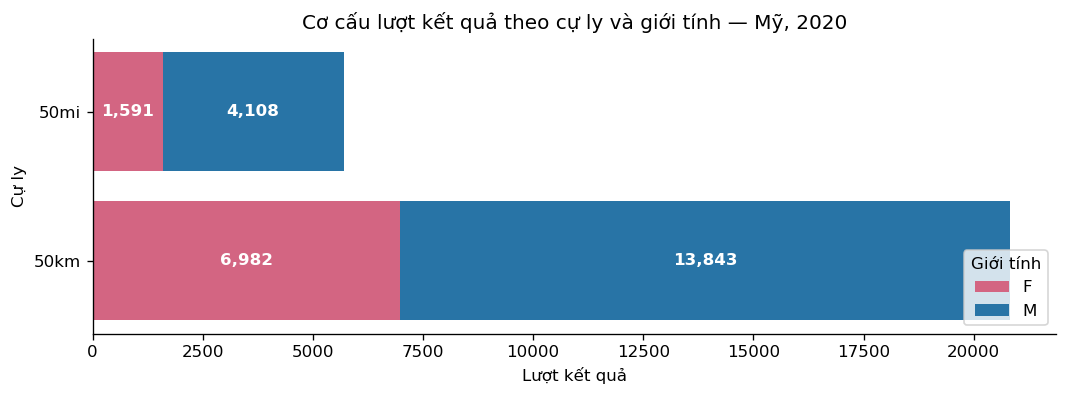

In [6]:
participation = clean.groupby(["distance", "gender"]).agg(
    observations=("athlete_id", "size"), source_ids=("athlete_id", "nunique"),
    race_editions=("race_id", "nunique")).reset_index()
participation["share_within_distance_pct"] = 100 * participation.observations / participation.groupby("distance").observations.transform("sum")
table(participation, 2)
counts = participation.pivot(index="distance", columns="gender", values="observations").fillna(0).reindex(["50km", "50mi"])
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(counts))
for gender in ["F", "M"]:
    values = counts[gender].to_numpy()
    ax.barh(counts.index, values, left=left, color=COLORS[gender], label=gender)
    for i, value in enumerate(values):
        ax.text(left[i] + value / 2, i, f"{int(value):,}", ha="center", va="center", color="white", fontweight="bold")
    left += values
ax.set(xlabel="Lượt kết quả", ylabel="Cự ly", title="Cơ cấu lượt kết quả theo cự ly và giới tính — Mỹ, 2020")
ax.legend(title="Giới tính", loc="lower right")
save_figure(fig, "01_participation.png")

## 4. Tốc độ theo cự ly và giới tính
Cả hai cự ly dùng đơn vị **km/h**. Bảng trình bày trung bình, trung vị và tứ phân vị. Trong biểu đồ hộp, hộp trải từ Q1 đến Q3, đường giữa là trung vị; các điểm ngoài râu hộp được ẩn để dễ đọc nhưng vẫn có trong phép tính.

,distance,gender,observations,source_ids,mean_kmh,median_kmh,q25_kmh,q75_kmh
0,50km,F,6982,6030,7.093,6.933,6.029,7.992
1,50km,M,13843,11661,7.742,7.507,6.497,8.747
2,50mi,F,1591,1526,6.826,6.677,5.931,7.572
3,50mi,M,4108,3880,7.246,6.998,6.197,8.104


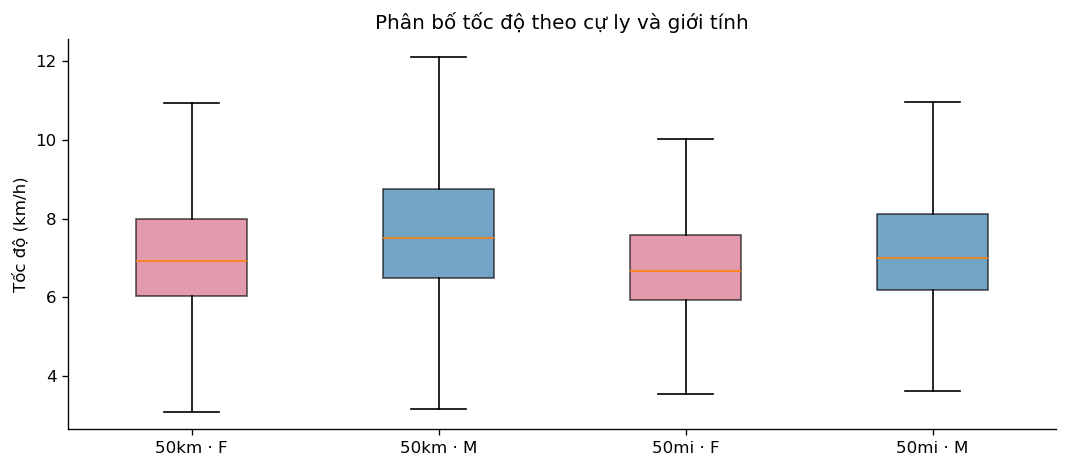

In [7]:
speed_summary = clean.groupby(["distance", "gender"]).agg(
    observations=("speed_kmh", "size"), source_ids=("athlete_id", "nunique"),
    mean_kmh=("speed_kmh", "mean"), median_kmh=("speed_kmh", "median"),
    q25_kmh=("speed_kmh", lambda s: s.quantile(.25)), q75_kmh=("speed_kmh", lambda s: s.quantile(.75))).reset_index()
table(speed_summary)
groups = [(distance, gender) for distance in ["50km", "50mi"] for gender in ["F", "M"]]
fig, ax = plt.subplots(figsize=(9, 4))
boxes = ax.boxplot([clean.loc[clean.distance.eq(x) & clean.gender.eq(g), "speed_kmh"].astype(float)
                    for x, g in groups], tick_labels=[f"{x} · {g}" for x,g in groups],
                   showfliers=False, patch_artist=True)
for patch, (_, gender) in zip(boxes["boxes"], groups):
    patch.set_facecolor(COLORS[gender]); patch.set_alpha(.65)
ax.set(ylabel="Tốc độ (km/h)", title="Phân bố tốc độ theo cự ly và giới tính")
save_figure(fig, "02_speed_distribution.png")

Các so sánh dưới đây chưa điều chỉnh tuổi, địa hình, độ cao hay kinh nghiệm thi đấu. Phạm vi diễn giải được nêu trong mục Giới hạn.

## 5. Tuổi và tốc độ
Phần này chỉ dùng lượt có tuổi hợp lệ. Các tuổi được gộp thành nhóm để tránh xếp hạng từ vài quan sát; biểu đồ chỉ hiển thị nhóm có ít nhất 30 lượt. Nhóm 0–19 vẫn được giữ nếu tuổi vượt qua các bước kiểm tra dữ liệu.

,distance,age_group,observations,source_ids,mean_kmh,median_kmh,shown_on_chart
0,50km,0–19,143,131,7.782,7.496,True
1,50km,20–29,2482,2258,8.052,7.822,True
2,50km,30–39,6180,5434,7.799,7.559,True
3,50km,40–49,6618,5624,7.448,7.274,True
4,50km,50–59,3967,3213,7.170,7.000,True
5,50km,60–69,1090,860,6.697,6.641,True
6,50km,70–100,152,120,6.077,6.054,True
7,50mi,0–19,41,41,7.199,7.087,True
8,50mi,20–29,769,747,7.493,7.205,True
9,50mi,30–39,1855,1782,7.363,7.132,True


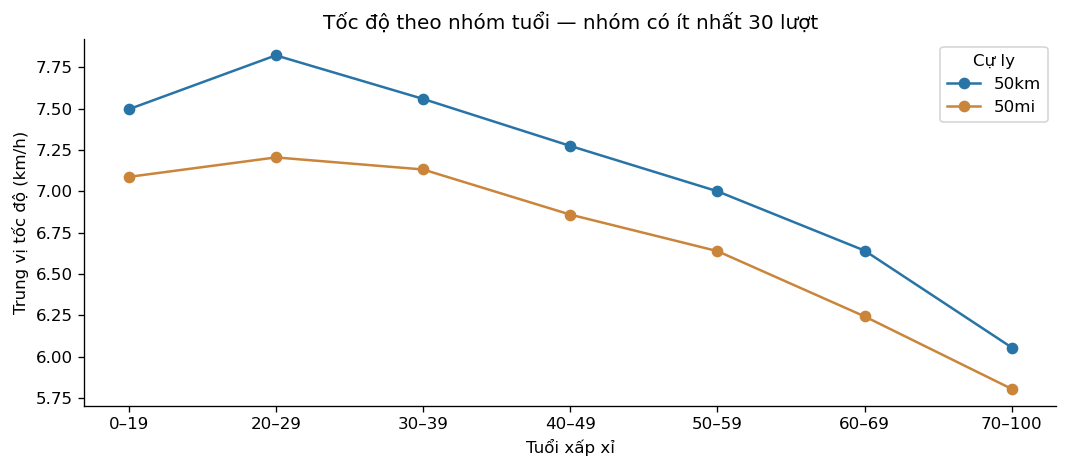

In [8]:
AGE_LABELS = ["0–19", "20–29", "30–39", "40–49", "50–59", "60–69", "70–100"]
age_data = clean.loc[clean.age.notna()].copy()
age_data["age_group"] = pd.cut(age_data.age.astype(float), bins=[-1,19,29,39,49,59,69,100], labels=AGE_LABELS)
age_summary = age_data.groupby(["distance", "age_group"], observed=True).agg(
    observations=("speed_kmh", "size"), source_ids=("athlete_id", "nunique"),
    mean_kmh=("speed_kmh", "mean"), median_kmh=("speed_kmh", "median")).reset_index()
age_summary["shown_on_chart"] = age_summary.observations.ge(MIN_AGE_OBSERVATIONS)
table(age_summary)
fig, ax = plt.subplots(figsize=(9, 4))
for distance, color in [("50km", "#2874a6"), ("50mi", "#ca853b")]:
    group = age_summary.loc[age_summary.distance.eq(distance)].set_index("age_group").reindex(AGE_LABELS)
    values = group.median_kmh.where(group.observations.ge(MIN_AGE_OBSERVATIONS))
    ax.plot(AGE_LABELS, values, marker="o", label=distance, color=color)
ax.set(xlabel="Tuổi xấp xỉ", ylabel="Trung vị tốc độ (km/h)", title="Tốc độ theo nhóm tuổi — nhóm có ít nhất 30 lượt")
ax.legend(title="Cự ly")
save_figure(fig, "03_age_groups.png")

### So sánh mẫu có tuổi và thiếu tuổi
So sánh tốc độ giữa hai mẫu để xem việc loại tuổi thiếu làm thay đổi thống kê đến đâu. Phân tích giới tính và mùa dùng cả hai mẫu; phân tích tuổi chỉ dùng mẫu có tuổi hợp lệ.

In [9]:
age_missing_sensitivity = clean.assign(age_status=np.where(clean.age.isna(), "Tuổi chưa biết", "Có tuổi")).groupby(
    ["distance", "age_status"]).agg(observations=("speed_kmh", "size"), mean_kmh=("speed_kmh", "mean"),
                                  median_kmh=("speed_kmh", "median")).reset_index()
table(age_missing_sensitivity)

,distance,age_status,observations,mean_kmh,median_kmh
0,50km,Có tuổi,20632,7.525,7.308
1,50km,Tuổi chưa biết,193,7.488,7.238
2,50mi,Có tuổi,5657,7.133,6.910
3,50mi,Tuổi chưa biết,42,6.606,6.331


## 6. Mùa và thành tích: tách cự ly, kiểm tra trọng số
So sánh mùa riêng cho mỗi cự ly. **Mean theo lượt** cho giải đông người trọng số lớn hơn. **Mean của mean từng phiên giải** cho mỗi phiên giải/cự ly trọng số bằng nhau. Hai cách trả lời hai câu hỏi khác nhau: thành tích của một lượt điển hình và tốc độ trung bình của một phiên giải điển hình trong dữ liệu.

,distance,season,observations,source_ids,race_editions,mean_kmh,median_kmh,equal_event_mean_kmh
0,50km,Winter,9399,8583,152,7.655,7.425,7.747
1,50km,Spring,2601,2576,40,7.893,7.546,7.621
2,50km,Summer,2084,1989,50,6.962,6.725,7.212
3,50km,Fall,6741,6328,136,7.374,7.192,7.471
4,50mi,Winter,1519,1495,37,7.171,6.979,7.182
5,50mi,Spring,847,846,17,7.073,6.772,7.216
6,50mi,Summer,869,861,20,6.514,6.251,6.830
7,50mi,Fall,2464,2414,50,7.339,7.098,7.114


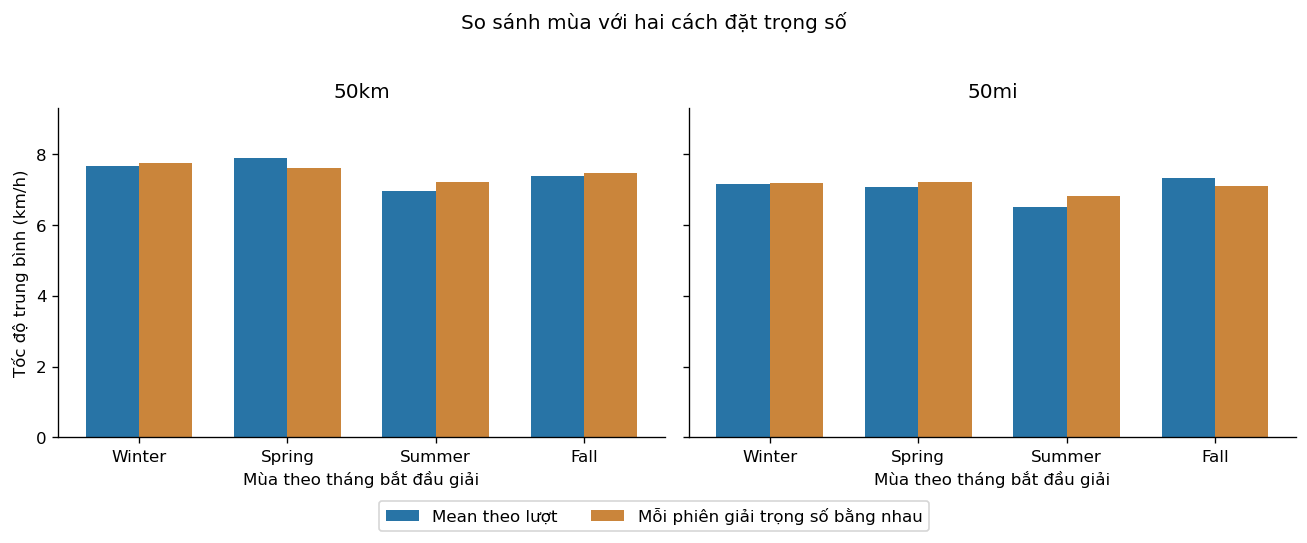

In [10]:
season_summary = clean.groupby(["distance", "season"], observed=True).agg(
    observations=("speed_kmh", "size"), source_ids=("athlete_id", "nunique"),
    race_editions=("race_id", "nunique"), mean_kmh=("speed_kmh", "mean"),
    median_kmh=("speed_kmh", "median")).reset_index()
event_means = clean.groupby(["distance", "season", "race_id"], observed=True).agg(
    observations=("speed_kmh", "size"), event_mean_kmh=("speed_kmh", "mean")).reset_index()
equal_event = event_means.groupby(["distance", "season"], observed=True).event_mean_kmh.mean().rename("equal_event_mean_kmh").reset_index()
season_summary = season_summary.merge(equal_event, on=["distance", "season"], validate="one_to_one")
table(season_summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, distance in zip(axes, ["50km", "50mi"]):
    s = season_summary.loc[season_summary.distance.eq(distance)].set_index("season").reindex(SEASONS)
    x = np.arange(4)
    ax.bar(x-.18, s.mean_kmh, .36, label="Mean theo lượt", color="#2874a6")
    ax.bar(x+.18, s.equal_event_mean_kmh, .36, label="Mỗi phiên giải trọng số bằng nhau", color="#ca853b")
    ax.set(xticks=x, xticklabels=SEASONS, title=distance, xlabel="Mùa theo tháng bắt đầu giải")
    ax.set_ylim(0, max(season_summary.mean_kmh.max(), season_summary.equal_event_mean_kmh.max()) * 1.18)
axes[0].set_ylabel("Tốc độ trung bình (km/h)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(.5, -.07), ncol=2)
fig.suptitle("So sánh mùa với hai cách đặt trọng số", y=1.03)
save_figure(fig, "04_season_sensitivity.png")

Thành phần giải và người tham dự thay đổi giữa các mùa. Vì chưa có nhiệt độ, địa hình và độ cao, phần này chỉ mô tả khác biệt theo tháng trong mẫu năm 2020.

## 7. Người chạy nhiều lần và so sánh trong cùng phiên giải
Loại các ID mâu thuẫn rồi tính tốc độ trung bình của từng ID/cự ly. So sánh `mean_matching_subset_kmh` và `mean_per_athlete_kmh` trên cùng tập ID để đo ảnh hưởng của việc đổi trọng số từ lượt sang ID. Cột `mean_kmh` giữ thống kê mẫu đầy đủ làm tham chiếu.

Phép đối chiếu thứ hai tính chênh lệch trung bình M−F trong những phiên giải có ít nhất 10 lượt mỗi nhóm.

In [11]:
athlete_stats = identity_clean.groupby(["distance", "gender", "athlete_id"]).agg(
    observations=("speed_kmh", "size"), athlete_mean_kmh=("speed_kmh", "mean")).reset_index()
person_weighted = athlete_stats.groupby(["distance", "gender"]).agg(
    eligible_source_ids=("athlete_id", "size"), repeat_source_ids=("observations", lambda s: s.gt(1).sum()),
    mean_per_athlete_kmh=("athlete_mean_kmh", "mean")).reset_index()
matching_subset = identity_clean.groupby(["distance", "gender"]).speed_kmh.mean().rename("mean_matching_subset_kmh").reset_index()
weight_sensitivity = speed_summary[["distance", "gender", "mean_kmh"]].merge(
    person_weighted, on=["distance", "gender"], validate="one_to_one")
weight_sensitivity = weight_sensitivity.merge(matching_subset, on=["distance", "gender"], validate="one_to_one")
table(weight_sensitivity)

within_race = clean.loc[clean.gender.isin(["M", "F"])].groupby(["distance", "race_id", "gender"]).agg(
    n=("speed_kmh", "size"), mean=("speed_kmh", "mean")).unstack("gender")
eligible = within_race.loc[(within_race[("n", "M")] >= 10) & (within_race[("n", "F")] >= 10)].copy()
eligible["gap_m_minus_f"] = eligible[("mean", "M")] - eligible[("mean", "F")]
within_race_summary = eligible.groupby(level="distance")["gap_m_minus_f"].agg(
    eligible_race_editions="size", mean_gap_kmh="mean", median_gap_kmh="median").reset_index()
table(within_race_summary)

,distance,gender,mean_kmh,eligible_source_ids,repeat_source_ids,mean_per_athlete_kmh,mean_matching_subset_kmh
0,50km,F,7.093,5992,692,7.092,7.094
1,50km,M,7.742,11452,1454,7.730,7.736
2,50mi,F,6.826,1512,56,6.819,6.819
3,50mi,M,7.246,3770,181,7.240,7.242


,distance,eligible_race_editions,mean_gap_kmh,median_gap_kmh
0,50km,220,0.748,0.738
1,50mi,45,0.475,0.488


## 8. Kết quả chính
Các số dưới đây được tổng hợp từ các bảng phân tích ở trên.

In [12]:
summary_lines = [f"**Phạm vi:** {len(clean):,} lượt kết quả, {clean.athlete_id.nunique():,} ID nguồn "
                 f"tại {clean.race_id.nunique():,} phiên giải/cự ly tại Mỹ năm {YEAR}.",
    f"**Kiểm tra dữ liệu:** phục hồi {len(missed):,} lượt mà cách lấy ngoặc đầu tiên bỏ sót; "
    f"giữ {clean.age.isna().sum():,} lượt thiếu tuổi cho các phân tích không dùng tuổi. "
    f"{len(quarantine):,} lượt bị cách ly vì kiểm tra tốc độ/thời gian.",
    f"**Nhận dạng:** {len(ambiguous_ids):,} ID mâu thuẫn, liên quan {len(identity_conflicts):,} lượt; "
    "giữ các lượt cho mô tả thành tích, loại những ID này khỏi kiểm tra trọng số theo người. Số ID nguồn không xác nhận số người duy nhất."]
for distance in ["50km", "50mi"]:
    group = speed_summary.loc[speed_summary.distance.eq(distance)].set_index("gender")
    m, f = group.loc["M"], group.loc["F"]
    summary_lines.append(f"**{distance}, giới tính:** trung bình M {m.mean_kmh:.2f} và F {f.mean_kmh:.2f} km/h "
        f"(chênh {m.mean_kmh-f.mean_kmh:.2f}); trung vị M {m.median_kmh:.2f} và F {f.median_kmh:.2f}. "
        "")
    s = season_summary.loc[season_summary.distance.eq(distance)].set_index("season")
    summary_lines.append(f"**{distance}, mùa:** trung bình theo lượt vào mùa hè {s.loc['Summer','mean_kmh']:.2f}, "
        f"mùa đông {s.loc['Winter','mean_kmh']:.2f} km/h; khi cho mỗi phiên giải trọng số bằng nhau, "
        f"hai giá trị là {s.loc['Summer','equal_event_mean_kmh']:.2f} và {s.loc['Winter','equal_event_mean_kmh']:.2f}. "
        "")
    a = age_summary.loc[age_summary.distance.eq(distance) & age_summary.shown_on_chart].sort_values("median_kmh", ascending=False).iloc[0]
    summary_lines.append(f"**{distance}, tuổi:** nhóm {a.age_group} có trung vị cao nhất trong các nhóm đủ ngưỡng "
        f"({a.median_kmh:.2f} km/h, {a.observations:,} lượt). ")
    w = weight_sensitivity.loc[weight_sensitivity.distance.eq(distance)]
    change = (w.mean_per_athlete_kmh - w.mean_matching_subset_kmh).abs().max()
    summary_lines.append(f"**{distance}, trọng số theo ID:** trên mẫu đã loại ID mâu thuẫn, chuyển từ trọng số theo lượt "
        f"sang theo ID làm tốc độ trung bình mỗi nhóm giới tính thay đổi tối đa {change:.3f} km/h. "
        "")
    within = within_race_summary.loc[within_race_summary.distance.eq(distance)].iloc[0]
    summary_lines.append(f"**{distance}, trong cùng phiên giải:** trung vị chênh lệch tốc độ trung bình M−F là "
        f"{within.median_gap_kmh:.2f} km/h, trên {int(within.eligible_race_editions)} phiên đủ ít nhất 10 lượt mỗi nhóm. "
        "")
display(Markdown("\n\n".join(summary_lines)))

**Phạm vi:** 26,524 lượt kết quả, 21,594 ID nguồn tại 502 phiên giải/cự ly tại Mỹ năm 2020.

**Kiểm tra dữ liệu:** phục hồi 434 lượt mà cách lấy ngoặc đầu tiên bỏ sót; giữ 235 lượt thiếu tuổi cho các phân tích không dùng tuổi. 0 lượt bị cách ly vì kiểm tra tốc độ/thời gian.

**Nhận dạng:** 255 ID mâu thuẫn, liên quan 687 lượt; giữ các lượt cho mô tả thành tích, loại những ID này khỏi kiểm tra trọng số theo người. Số ID nguồn không xác nhận số người duy nhất.

**50km, giới tính:** trung bình M 7.74 và F 7.09 km/h (chênh 0.65); trung vị M 7.51 và F 6.93. 

**50km, mùa:** trung bình theo lượt vào mùa hè 6.96, mùa đông 7.65 km/h; khi cho mỗi phiên giải trọng số bằng nhau, hai giá trị là 7.21 và 7.75. 

**50km, tuổi:** nhóm 20–29 có trung vị cao nhất trong các nhóm đủ ngưỡng (7.82 km/h, 2,482 lượt). 

**50km, trọng số theo ID:** trên mẫu đã loại ID mâu thuẫn, chuyển từ trọng số theo lượt sang theo ID làm tốc độ trung bình mỗi nhóm giới tính thay đổi tối đa 0.006 km/h. 

**50km, trong cùng phiên giải:** trung vị chênh lệch tốc độ trung bình M−F là 0.74 km/h, trên 220 phiên đủ ít nhất 10 lượt mỗi nhóm. 

**50mi, giới tính:** trung bình M 7.25 và F 6.83 km/h (chênh 0.42); trung vị M 7.00 và F 6.68. 

**50mi, mùa:** trung bình theo lượt vào mùa hè 6.51, mùa đông 7.17 km/h; khi cho mỗi phiên giải trọng số bằng nhau, hai giá trị là 6.83 và 7.18. 

**50mi, tuổi:** nhóm 20–29 có trung vị cao nhất trong các nhóm đủ ngưỡng (7.21 km/h, 769 lượt). 

**50mi, trọng số theo ID:** trên mẫu đã loại ID mâu thuẫn, chuyển từ trọng số theo lượt sang theo ID làm tốc độ trung bình mỗi nhóm giới tính thay đổi tối đa 0.002 km/h. 

**50mi, trong cùng phiên giải:** trung vị chênh lệch tốc độ trung bình M−F là 0.49 km/h, trên 45 phiên đủ ít nhất 10 lượt mỗi nhóm. 

### Hướng sử dụng kết quả
- **Cơ cấu người tham dự:** kết quả mô tả các lượt có trong nguồn. Để đánh giá khả năng thu hút người mới hoặc tỷ lệ hoàn thành, cần thêm dữ liệu đăng ký, xuất phát và bỏ cuộc.
- **Vận hành giải:** phân bố thời gian và tốc độ là dữ liệu tham khảo khi bố trí hỗ trợ. Giờ đóng trạm còn phụ thuộc đường đua, thời tiết và quy định của từng giải.
- **Phân tích tiếp:** bổ sung nhiều năm dữ liệu, nhiệt độ, độ cao tích lũy và loại đường đua; so sánh cùng giải qua thời gian hoặc cùng người chạy.

### Giới hạn
1. Nguồn chỉ có các bản ghi kết quả, thiếu tổng người đăng ký và xuất phát nên không tính được tỷ lệ hoàn thành.
2. Dữ liệu có thể chưa bao phủ toàn bộ giải tại Mỹ. Khóa phiên giải/cự ly do dự án quy ước, không phải mã sự kiện chính thức.
3. Athlete ID có mâu thuẫn năm sinh, giới tính và tổ hợp kết quả. Phân tích trọng số theo người đã loại các ID phát hiện mâu thuẫn; các trường hợp gộp hoặc tách ID khác vẫn có thể còn tồn tại.
4. Tuổi được ước tính từ năm sinh; có 235 lượt thiếu tuổi. Phân tích tuổi dùng mẫu nhỏ hơn và có thể chịu sai lệch lựa chọn.
5. Tên giải được giữ như trong nguồn, kể cả các ký tự lỗi chưa xác minh được.
6. Đây là phân tích mô tả, chưa kiểm định tác động của tuổi, giới tính hay thời tiết lên tốc độ. Các mức trung bình không phải mục tiêu tập luyện cá nhân.

## 9. Lưu kết quả và đối chiếu
Bảng tổng hợp, dữ liệu phân tích và biểu đồ được lưu trong `results/`. Các kiểm tra cuối bài đối chiếu tổng dòng, cơ cấu nhóm, định dạng ngày và tốc độ tính từ thời gian hoàn thành. CSV nguồn được giữ nguyên.

In [13]:
assert len(clean) + len(quarantine) == len(raw)
assert participation.observations.sum() == len(clean)
assert speed_summary.observations.sum() == len(clean)
assert season_summary.observations.sum() == len(clean)
assert age_summary.observations.sum() == clean.age.notna().sum()
assert clean.speed_difference.le(SPEED_TOLERANCE).all()
tables = {"quality_checks": quality, "overview": overview, "filter_difference": filter_difference,
    "participation": participation, "speed_summary": speed_summary, "age_summary": age_summary,
    "age_missing_sensitivity": age_missing_sensitivity, "season_summary": season_summary,
    "weight_sensitivity": weight_sensitivity, "within_race_summary": within_race_summary}
for name, frame in tables.items():
    frame.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")
clean.drop(columns=["duration"]).to_csv(OUT / "analysis_data.csv", index=False, encoding="utf-8-sig")
identity_conflicts.drop(columns=["duration"]).to_csv(OUT / "identity_conflicts.csv", index=False, encoding="utf-8-sig")
validation = {"input_sha256": data_sha256, "loaded_rows": loaded_rows, "scope_rows": len(raw),
    "analysis_rows": len(clean), "source_ids": clean.athlete_id.nunique(), "race_editions": clean.race_id.nunique(),
    "ambiguous_ids": len(ambiguous_ids), "identity_conflict_rows": len(identity_conflicts),
    "missing_age_rows": int(clean.age.isna().sum()), "filter_recovered_rows": len(missed),
    "quarantined_rows": len(quarantine), "max_speed_difference_kmh": float(clean.speed_difference.max()),
    "environment": {"Python": platform.python_version(), "pandas": pd.__version__,
                    "numpy": np.__version__, "matplotlib": matplotlib.__version__},
    "checks": "Row totals, grouping totals, date formats and speed-time reconciliation passed."}
(OUT / "validation.json").write_text(json.dumps(validation, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đối chiếu đạt. Đã lưu", len(tables), "bảng tổng hợp, dữ liệu phân tích và 4 biểu đồ vào results/.")

Đối chiếu đạt. Đã lưu 10 bảng tổng hợp, dữ liệu phân tích và 4 biểu đồ vào results/.


## Nguồn và tài liệu
- Dữ liệu: [The big dataset of ultra-marathon running — Kaggle](https://www.kaggle.com/datasets/aiaiaidavid/the-big-dataset-of-ultra-marathon-running), từ file `TWO_CENTURIES_OF_UM_RACES.csv`. Số dòng và SHA-256 của bản dùng trong dự án được ghi trong `data/manifest.json`.
- Bài thực hành ban đầu được làm theo tutorial; hiện chưa tìm lại được đường dẫn gốc.
- Tài liệu kỹ thuật: [pandas.read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html), [pandas.DataFrame.reset_index](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html), [pandas.to_datetime](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html), [Matplotlib boxplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.boxplot.html).